# Images and Priors

In [1]:
import numpy as np
import os
import pandas as pd
# plot
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
# import seaborn as sns

fig_dir = "prior_celeb/figure"
os.makedirs(fig_dir, exist_ok=True)

NORMALIZE = True  # whether to normalize the offset of the prior

MODEL_DIR = "../models_mnist/"
INVERT_MODE = "cvx_cg"
perturb_mode = "gaussian"

# prior_name = "prior_idood_cifar"
# model_name = 'cifar'
prior_name = "prior_idood_noAug_1"
model_name = 'mnist'
seeds = [5678, 7890, 7618, 2024, 2025]
seeds = [1234, 5678, 7890, 2024, 2025, 6092, 7220, 7478, 3508, 7879]
seed = seeds[1]
prior_name = prior_name + f'_{seed}'
# for seed in seeds:
#     prior_name = prior_name + f'_{seed}'
#     break
print(prior_name)
# model_name = 'cifar'
PRIOR_DIR = os.path.join(MODEL_DIR, prior_name)
result_dir = os.path.join(PRIOR_DIR, INVERT_MODE, perturb_mode, "all")

if model_name == 'cifar':
    img_size = (32, 32)
    model_name = prior_name[-5:]
else:
    img_size = (28, 28)
    model_name = 'mnist'

data_dist = ['cifar', 'mnist']

prior_idood_noAug_1_5678


In [2]:
# visualization settings
idx_map = {
    "gaussian": [0, 4],
    "gaussian_clip": [0, 4],
    "blur": [26, 30],
    "convex": [3, 5],
}
idx_list = idx_map[perturb_mode]
col_idx = None


# load data
df = pd.read_csv(os.path.join(result_dir, "prior.csv"))

In [3]:
if NORMALIZE:
    min_val = df.min().min()
    df = df - min_val
    df_ = df
df_

,0.0,0.05,0.1,0.2,0.3
0,8.537758,10.397555,16.036602,39.728919,81.745044
1,3.031226,5.049204,10.354898,43.808132,126.682901
2,7.913899,10.140875,13.604423,39.668082,120.551246
3,5.551200,7.749639,13.330636,74.051661,114.202235
4,6.864110,9.199458,13.545640,39.091121,79.946472
...,...,...,...,...,...
995,2.702119,4.433971,12.081744,42.121814,81.736916
996,3.506317,5.211467,10.457018,46.325901,124.840178
997,7.914654,10.339694,13.251421,45.494706,141.051417
998,3.958166,6.246536,13.375059,42.163747,104.149191


In [39]:
model_name ='cifar'

labels_seeds = []
seeds = [7890]
for seed_idx, seed in enumerate(seeds):
    if model_name == 'mnist':
        prior_name = "prior_idood_noAug_1"
    else:
        prior_name = "prior_idood_cifar"
    # model_name = 'mnist'
    if model_name == 'cifar':
        label_list = np.load(f'{prior_name}/cvx_cg/gaussian/all/labels.npy')
    else:
        label_list = np.load(f'{prior_name}/cvx_cg/gaussian/all/labels.npy').astype(int)

    print(label_list)
    print(len(label_list))
    label_list_ = label_list
    
    # seeds = [0, 5678, 7890, 7618, 2024]
    # seeds = [5678, 7890, 1234, 2024, 2025]
    # seed = seeds[3]
    if seed == 0:
        pass
    else:    
        prior_name = prior_name + f'_{seed}'

    #     prior_name = prior_name + f'_{seed}'
    #     break
    print(prior_name)
    # model_name = 'cifar'
    PRIOR_DIR = os.path.join(MODEL_DIR, prior_name)
    result_dir = os.path.join(PRIOR_DIR, INVERT_MODE, perturb_mode, "all")

    

    data_dist = ['cifar', 'mnist']

    # visualization settings
    idx_map = {
        "gaussian": [0, 4],
        "gaussian_clip": [0, 4],
        "blur": [26, 30],
        "convex": [3, 5],
    }
    idx_list = idx_map[perturb_mode]
    col_idx = None


    # load data
    df = pd.read_csv(os.path.join(result_dir, "prior.csv"))

    if NORMALIZE:
        min_val = df.min().min()
        df = df - min_val
        df_ = df
    df_
    # if model_name == 'mnist':
    #     df__= df.iloc[:,0]
    #     df__ = df__.values
    #     labels = np.zeros((2, 10))
    #     for i in range(len(label_list)):
    #         labels[0,label_list_[i]] += 1
    #         labels[1,label_list_[i]] += [df__[i]]
    if model_name == 'mnist':
        df__ = df.iloc[:, 0]
        df__ = df__.values
        labels = [[] for _ in range(10)]  # 라벨별 값을 저장할 리스트 초기화

        for i in range(len(label_list)):
            labels[label_list_[i]].append(df__[i])  # 해당 라벨 리스트에 값 추가

    elif model_name == 'cifar':
        df__ = df.iloc[:, 0]
        df__ = df__.values
        labels = [[] for _ in range(10)]  # 라벨별 값을 저장할 리스트 초기화
        cnt = -1

        for i in range(len(label_list)):
            if i % 10 == 0:
                cnt += 1
            labels[cnt].append(df__[i])  # 해당 라벨 리스트에 값 추가

        # ID와 OOD 순서를 변경
        new_order = [0, 1, 2, 8, 9, 3, 4, 5, 6, 7]
        labels = [labels[i] for i in new_order]

        # 클래스 순서 변경
        classes = ['airplane', 'automobile', 'bird', 'ship', 'truck', 'cat', 'deer', 'dog', 'frog', 'horse']
        new_order = [3, 0, 1, 2, 4, 5, 6, 7, 8, 9]
        labels = [labels[i] for i in new_order]
        classes = [classes[i] for i in new_order]


    else:
        df__= df.iloc[:,0]
        df__ = df__.values

        labels = np.zeros((2, 6))
        # for i in range(50):
        #     labels[0,5] += 1
        #     labels[1,5] += df__[i]
        labels[0,5] = 50
        labels[1,5] = sum(df__[:50])
        for i in range(50,100):
            labels[0,label_list_[i]] += 1
            labels[1,label_list_[i]] += df__[i]

    print(labels[0])
    # labels[1]/labels[0]
    labels_np = np.array(labels)
    labels_seeds.append(labels_np)

['airplane' 'airplane' 'airplane' 'airplane' 'airplane' 'airplane'
 'airplane' 'airplane' 'airplane' 'airplane' 'automobile' 'automobile'
 'automobile' 'automobile' 'automobile' 'automobile' 'automobile'
 'automobile' 'automobile' 'automobile' 'bird' 'bird' 'bird' 'bird' 'bird'
 'bird' 'bird' 'bird' 'bird' 'bird' 'cat' 'cat' 'cat' 'cat' 'cat' 'cat'
 'cat' 'cat' 'cat' 'cat' 'deer' 'deer' 'deer' 'deer' 'deer' 'deer' 'deer'
 'deer' 'deer' 'deer' 'dog' 'dog' 'dog' 'dog' 'dog' 'dog' 'dog' 'dog'
 'dog' 'dog' 'frog' 'frog' 'frog' 'frog' 'frog' 'frog' 'frog' 'frog'
 'frog' 'frog' 'horse' 'horse' 'horse' 'horse' 'horse' 'horse' 'horse'
 'horse' 'horse' 'horse' 'ship' 'ship' 'ship' 'ship' 'ship' 'ship' 'ship'
 'ship' 'ship' 'ship' 'truck' 'truck' 'truck' 'truck' 'truck' 'truck'
 'truck' 'truck' 'truck' 'truck']
100
prior_idood_cifar_7890
[1.7807334570261446, 3.8396776029919693, 1.3506021418885439, 2.8416958415684803, 1.7306888601233368, 1.5081909391248018, 3.7197697032845554, 2.598646891477074, 

In [40]:
labels_seeds = np.array(labels_seeds)
print(labels_seeds.shape)
labels_std = np.std(labels_seeds, axis = 2)
print(labels_std.shape)
print(np.max(labels_std, axis = 1), np.min(labels_std, axis = 1))

(1, 10, 10)
(1, 10)
[1.97459663] [0.76761544]


In [30]:
labels_np.shape

(10, 100)

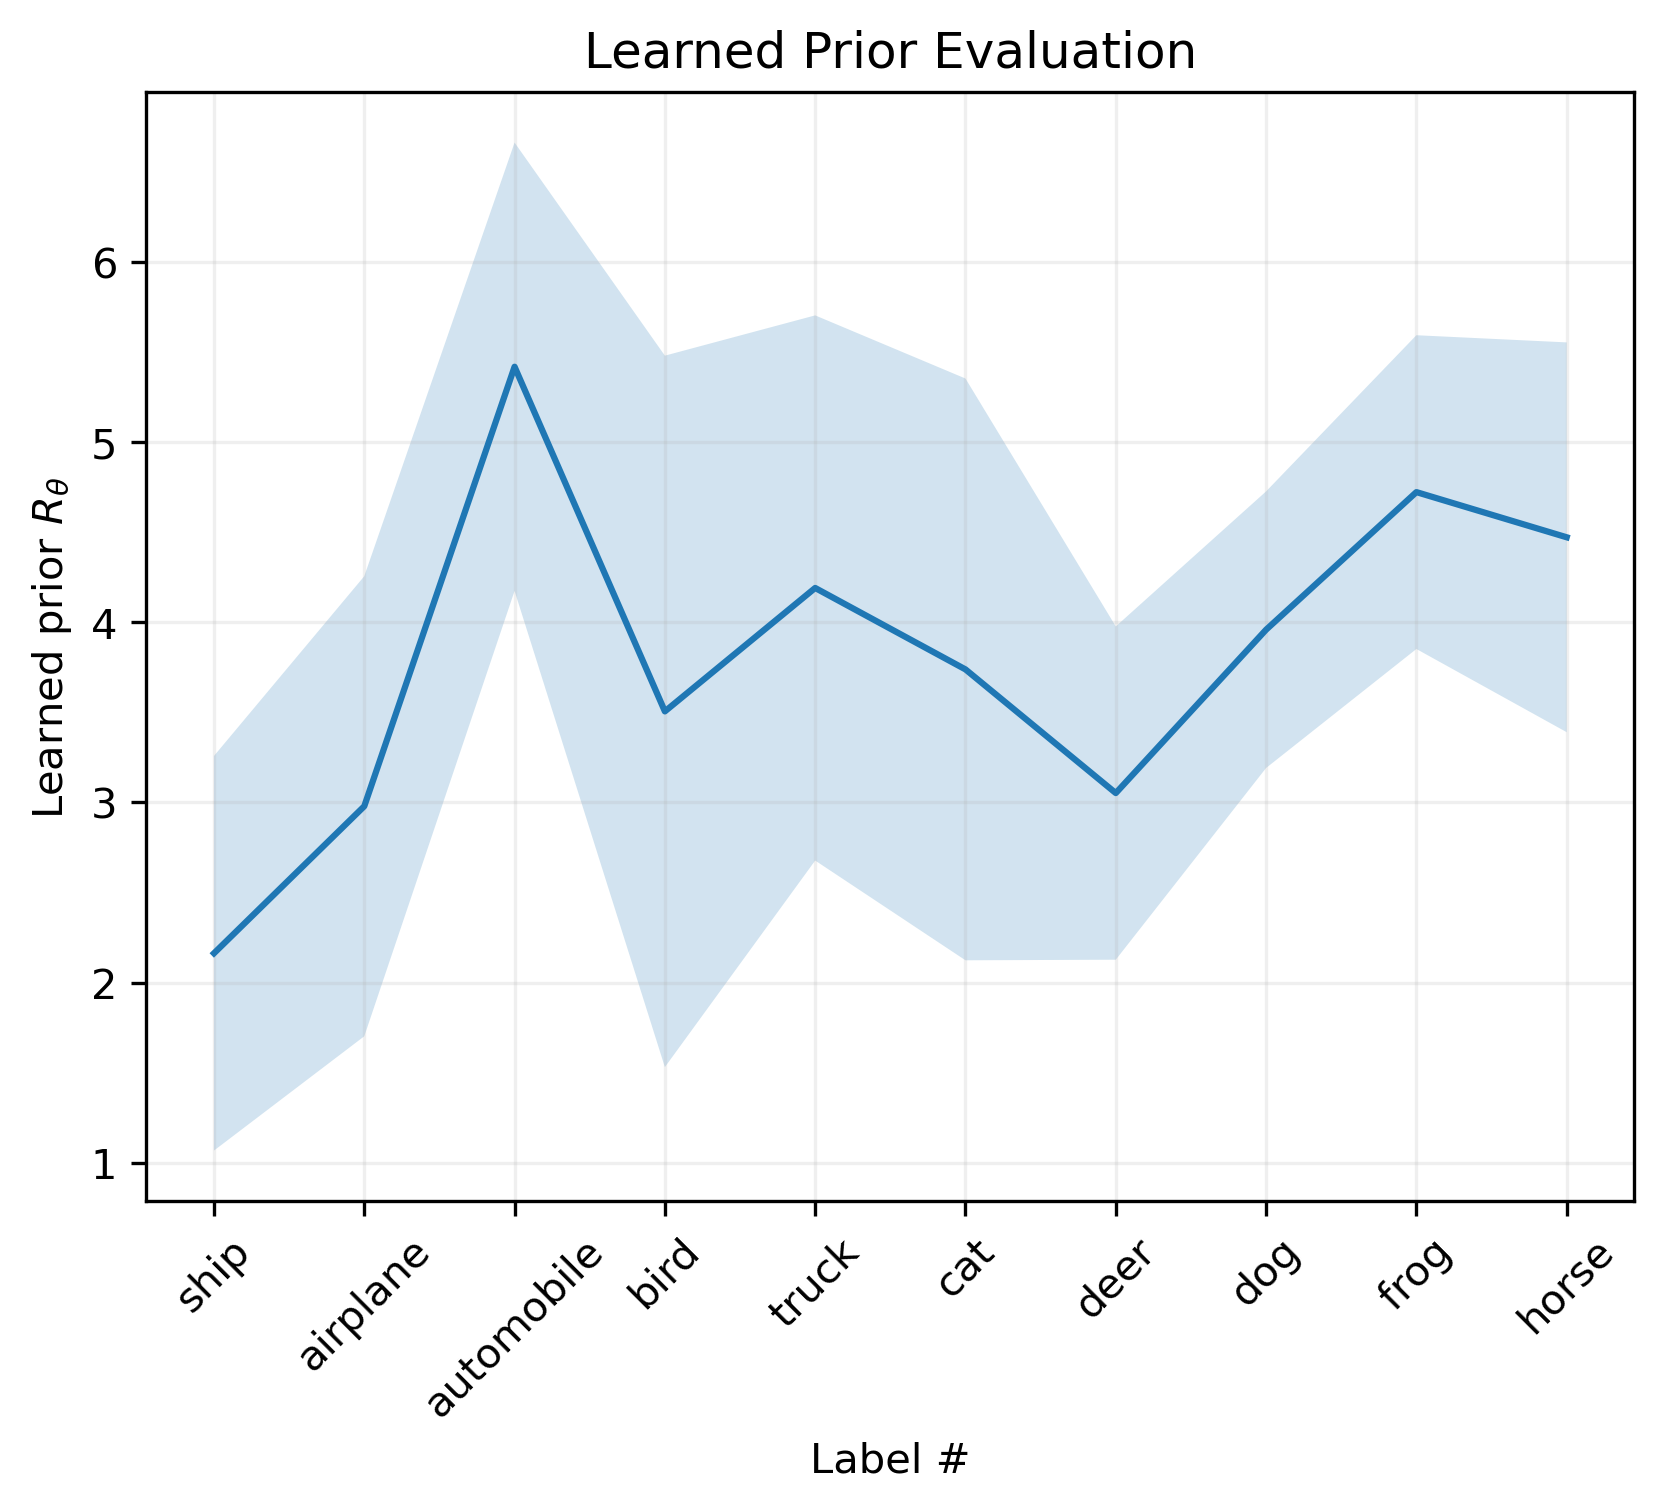

In [41]:
plt.figure(dpi=300)
if model_name in data_dist:
    x = np.linspace(0,9,10).astype(int)
    if model_name == 'cifar':
        x = classes
else:
    x = np.linspace(0,5,6).astype(int)
plt.plot(x,np.mean(labels_np, axis = 1))
plt.fill_between(x, np.mean(labels_np, axis = 1)+ np.std(labels_np, axis = 1), np.mean(labels_np, axis = 1)- np.std(labels_np, axis = 1), alpha = 0.2)
# plt.fill_between(x, np.mean(labels_np, axis = 1)+ np.max(labels_std, axis = 0), np.mean(labels_np, axis = 1)-np.min(labels_std, axis = 0), alpha = 0.2)
plt.xlabel('Label #')
plt.ylabel(r"Learned prior $R_\theta$")
plt.title('Learned Prior Evaluation')
if model_name in data_dist:
    if model_name == 'mnist':
        plt.xticks(range(0, 10, 1))
    else:
        plt.xticks(range(0, 10, 1), rotation = 45)
else:
    plt.title('label 0~4: MNIST, 5: CelebA')
    plt.xticks(range(0, 6, 1))
plt.grid('on', alpha = 0.2)
plt.show()


(100, 5, 784)
(100, 5)


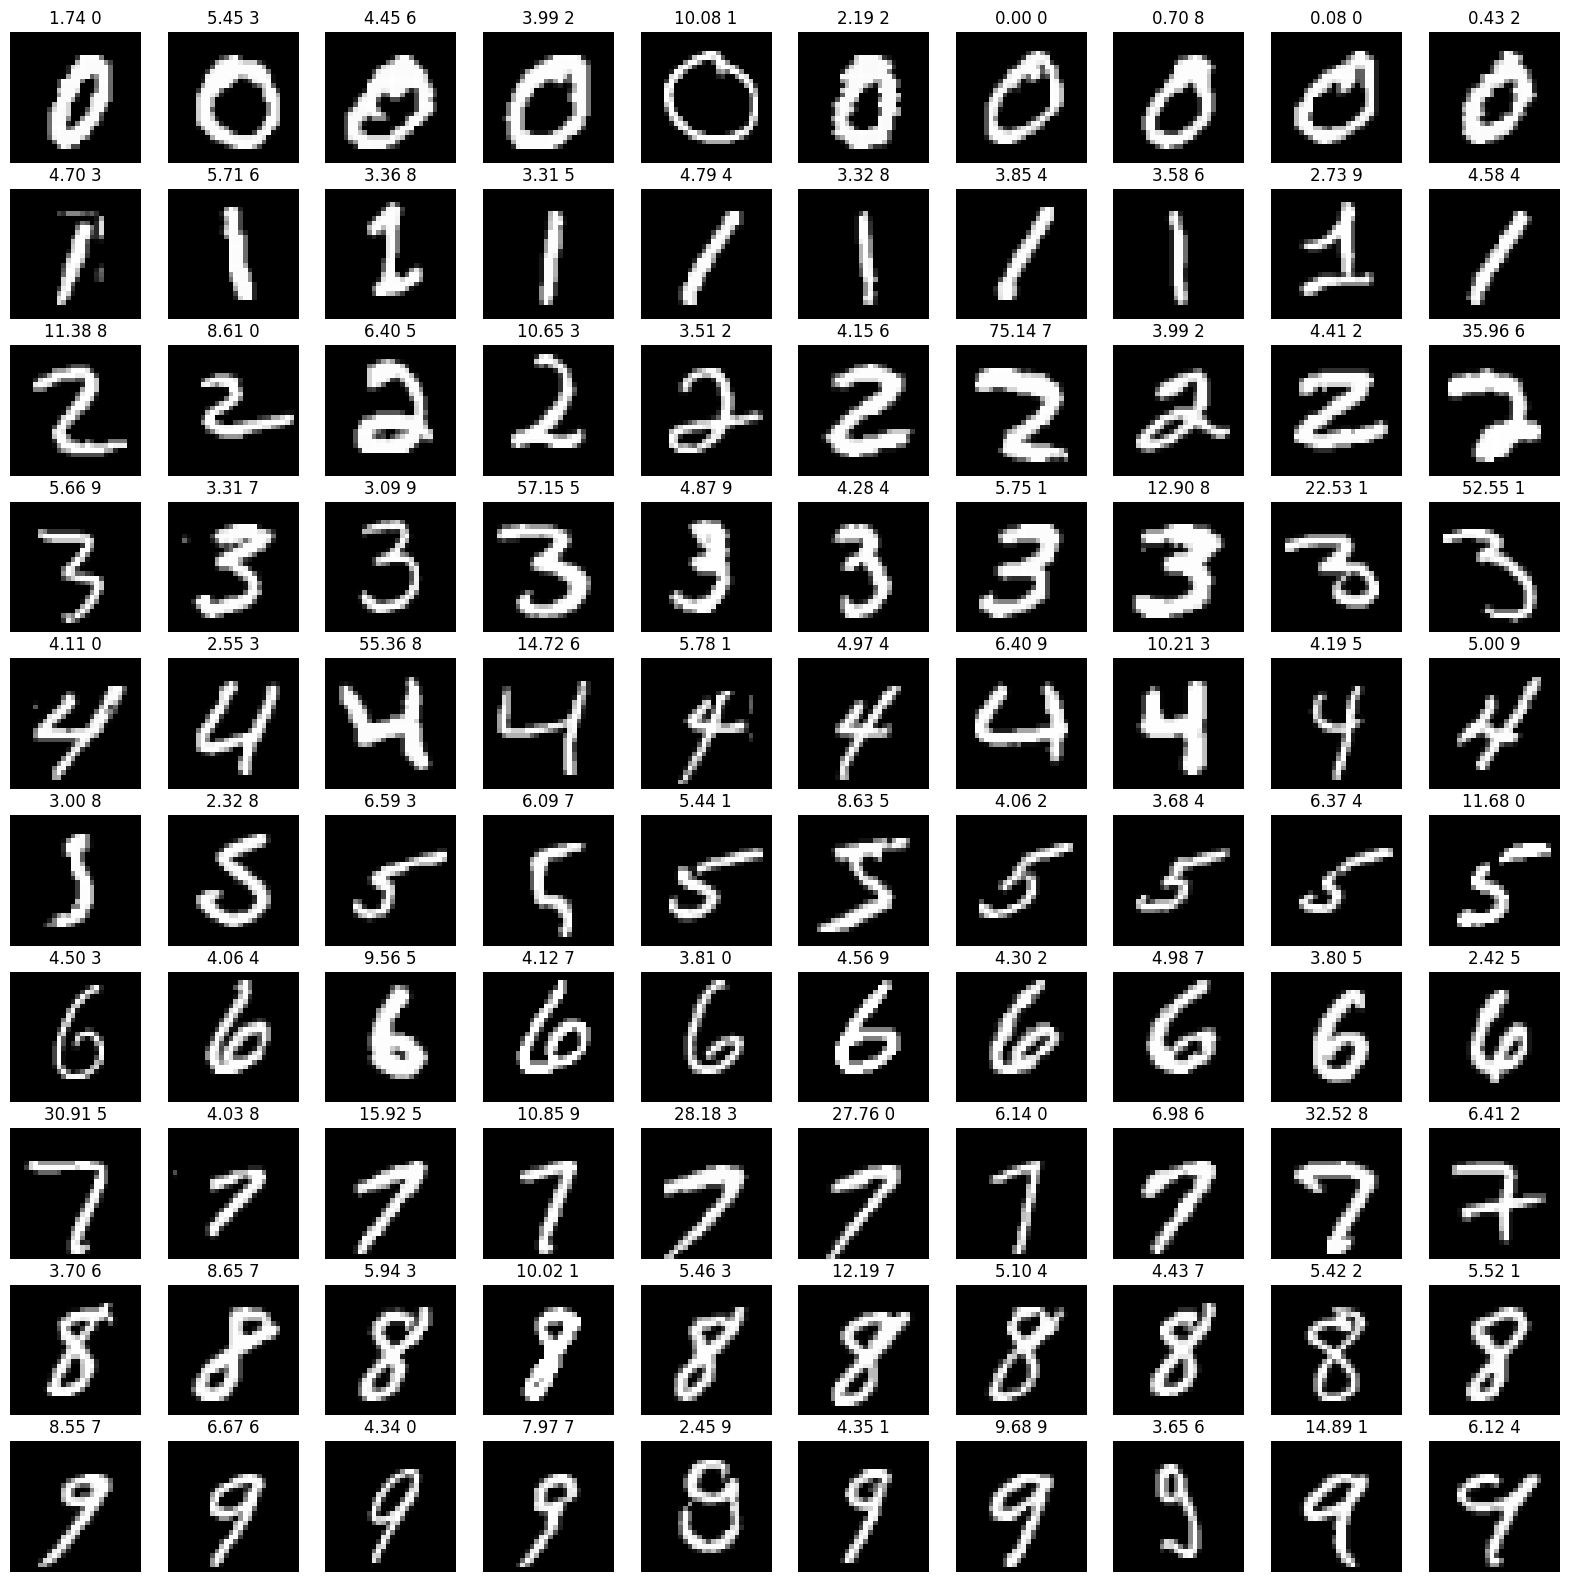

In [13]:
if col_idx is None:
    col_idx = np.arange(df.shape[1])
# df = df.iloc[idx_list, col_idx]
# p_array = df.values
x_arrays = np.zeros((5,100,5,784))
p_arrays = np.zeros((5,100,5))
sorted_indices = np.argsort(label_list)

x_array = np.load(os.path.join(result_dir, "x.npy"))
print(x_array.shape)
x_array_ = x_array[sorted_indices]
# x_array = x_array[idx_list, :, :][:, col_idx, :]

plt.figure(figsize = (20,20))
p_array_ = np.array(df_.values, dtype = np.float32)
p_array_ = p_array_[sorted_indices]
print(p_array_.shape)
label_list_ = label_list_[sorted_indices]
x_arrays[0] = x_array_
p_arrays[0] = p_array_
for i in range(100):
    plt.subplot(10,10,i+1)
    if model_name == 'cifar':
        plt.imshow(x_array_[i,0].squeeze().reshape(32,32))
    else:
        plt.imshow(x_array_[i,0].squeeze().reshape(28,28), cmap='gray')
    plt.grid(0)
    plt.axis('off')
    plt.title(f'{p_array_[i,0]:.2f} {label_list_[i]}')
    
plt.show()

In [9]:
classes
# classes = classes[new_order]
# classes = [classes[i] for i in new_order]
classes


['ship',
 'airplane',
 'automobile',
 'bird',
 'truck',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse']

In [ ]:
seeds = [1234, 5678, 7890, 2024, 2025, 6092, 7220, 7478, 3508, 7879]

p_arrays = np.zeros((len(seeds),100,5))

total_labels = np.zeros((len(seeds), 10))
model_name = 'cifar'
if model_name == 'cifar':
    img_size = (32, 32)
    # model_name = prior_name[-5:]
else:
    img_size = (28, 28)
    model_name = 'mnist'
x_arrays = np.zeros((len(seeds),100,5,img_size[0]*img_size[1]))

for seed_idx, seed in enumerate(seeds):
    if model_name == 'mnist':
        prior_name = "prior_idood_noAug_1"
    else:
        prior_name = "prior_idood_cifar"
    # model_name = 'mnist'
    
    # seeds = [0, 5678, 7890, 7618, 2024]
    # seeds = [5678, 7890, 1234, 2024, 2025]
    # seed = seeds[3]
    if seed == 0:
        pass
    else:    
        prior_name = prior_name + f'_{seed}'

    #     prior_name = prior_name + f'_{seed}'
    #     break
    print(prior_name)
    # model_name = 'cifar'
    PRIOR_DIR = os.path.join(MODEL_DIR, prior_name)
    result_dir = os.path.join(PRIOR_DIR, INVERT_MODE, perturb_mode, "all")

    

    data_dist = ['cifar', 'mnist']

    # visualization settings
    idx_map = {
        "gaussian": [0, 4],
        "gaussian_clip": [0, 4],
        "blur": [26, 30],
        "convex": [3, 5],
    }
    idx_list = idx_map[perturb_mode]
    col_idx = None


    # load data
    df = pd.read_csv(os.path.join(result_dir, "prior.csv"))

    if NORMALIZE:
        min_val = df.min().min()
        df = df - min_val
        df_ = df
    df_

    if model_name == 'cifar':
        label_list = np.load(f'{prior_name}/cvx_cg/gaussian/all/labels.npy')
    else:
        label_list = np.load(f'{prior_name}/cvx_cg/gaussian/all/labels.npy').astype(int)

    print(label_list)
    print(len(label_list))
    label_list_ = label_list

    if model_name == 'mnist':
        df__= df.iloc[:,0]
        df__ = df__.values
        labels = np.zeros((2, 10))
        for i in range(len(label_list)):
            labels[0,label_list_[i]] += 1
            labels[1,label_list_[i]] += df__[i]
    elif model_name == 'cifar':
        df__= df.iloc[:,0]
        df__ = df__.values
        labels = np.zeros((2, 10))
        cnt = -1
        for i in range(len(label_list)):
            if i % 10 == 0:
                cnt += 1
            labels[0,cnt] += 1
            labels[1,cnt] += df__[i]        
        # replacing into ID & OOD
        new_order = [0, 1, 2, 8, 9, 3, 4, 5, 6, 7]
        labels[0] = labels[0][new_order]
        labels[1] = labels[1][new_order]
        classes = ['airplane', 'automobile', 'bird', 'ship', 'truck', 'cat', 'deer', 'dog', 'frog', 'horse']
        new_order = [3, 0, 1, 2, 4, 5, 6, 7, 8 ,9]
        labels[0] = labels[0][new_order]
        labels[1] = labels[1][new_order]
        classes = [classes[i] for i in new_order]

    if model_name in data_dist:
        x = np.linspace(0,9,10).astype(int)
        if model_name == 'cifar':
            x = classes
    else:
        x = np.linspace(0,5,6).astype(int)
    total_labels[seed_idx] = labels[1]/labels[0]
    plt.plot(x,labels[1]/labels[0])
    # plt.fill_between(x, np.max(labels[1], ), np.min(labels[1]))
    plt.xlabel('label digit')
    plt.ylabel('mean prior value')
    if model_name in data_dist:
        if model_name == 'mnist':
            plt.xticks(range(0, 10, 1))
            plt.title('label 0: ID, 1~9: OOD')
        else:
            plt.title('label 0: ID, 1~9: OOD')
            plt.xticks(range(0, 10, 1), rotation = 45)
    else:
        plt.title('label 0~4: MNIST, 5: CelebA')
        plt.xticks(range(0, 6, 1))
    plt.grid(1)

    if col_idx is None:
        col_idx = np.arange(df.shape[1])
    # df = df.iloc[idx_list, col_idx]
    # p_array = df.values
    
    sorted_indices = np.argsort(label_list)

    x_array = np.load(os.path.join(result_dir, "x.npy"))
    print(x_array.shape)
    x_array_ = x_array[sorted_indices]
    # x_array = x_array[idx_list, :, :][:, col_idx, :]

    plt.figure(figsize = (20,20))
    p_array_ = np.array(df_.values, dtype = np.float32)
    p_array_ = p_array_[sorted_indices]
    print(p_array_.shape)
    label_list_ = label_list_[sorted_indices]
    x_arrays[seed_idx] = x_array_
    p_arrays[seed_idx] = p_array_
    for i in range(100):
        plt.subplot(10,10,i+1)
        if model_name == 'cifar':
            plt.imshow(x_array_[i,0].squeeze().reshape(32,32))
        else:
            plt.imshow(x_array_[i,0].squeeze().reshape(28,28), cmap='gray')
        plt.grid(0)
        plt.axis('off')
        plt.title(f'{p_array_[i,0]:.2f} {label_list_[i]}')
        
    plt.show()

mean_labels  = np.mean(total_labels, axis=0)
max_labels  = np.max(total_labels, axis=0)
min_labels  = np.min(total_labels, axis=0)
print(total_labels.shape)
print(total_labels)
print(mean_labels.shape)
plt.figure(dpi=300)
plt.plot(x,mean_labels)
plt.fill_between(x, max_labels, min_labels, alpha=0.2)
plt.xlabel('Label #')
plt.ylabel(r"Learned prior $R_\theta$")
plt.title('Learned Prior Evaluation')
if model_name in data_dist:
    if model_name == 'mnist':
        plt.xticks(range(0, 10, 1))

    else:
        
        plt.xticks(range(0, 10, 1), rotation = 45)
else:
    
    plt.xticks(range(0, 6, 1))
plt.grid(1)

prior_idood_cifar_1234
['airplane' 'airplane' 'airplane' 'airplane' 'airplane' 'airplane'
 'airplane' 'airplane' 'airplane' 'airplane' 'automobile' 'automobile'
 'automobile' 'automobile' 'automobile' 'automobile' 'automobile'
 'automobile' 'automobile' 'automobile' 'bird' 'bird' 'bird' 'bird' 'bird'
 'bird' 'bird' 'bird' 'bird' 'bird' 'cat' 'cat' 'cat' 'cat' 'cat' 'cat'
 'cat' 'cat' 'cat' 'cat' 'deer' 'deer' 'deer' 'deer' 'deer' 'deer' 'deer'
 'deer' 'deer' 'deer' 'dog' 'dog' 'dog' 'dog' 'dog' 'dog' 'dog' 'dog'
 'dog' 'dog' 'frog' 'frog' 'frog' 'frog' 'frog' 'frog' 'frog' 'frog'
 'frog' 'frog' 'horse' 'horse' 'horse' 'horse' 'horse' 'horse' 'horse'
 'horse' 'horse' 'horse' 'ship' 'ship' 'ship' 'ship' 'ship' 'ship' 'ship'
 'ship' 'ship' 'ship' 'truck' 'truck' 'truck' 'truck' 'truck' 'truck'
 'truck' 'truck' 'truck' 'truck']
100
prior_idood_cifar_5678
['airplane' 'airplane' 'airplane' 'airplane' 'airplane' 'airplane'
 'airplane' 'airplane' 'airplane' 'airplane' 'automobile' 'automobile'

TypeError: unsupported operand type(s) for /: 'list' and 'list'

(5, 10)
[[2.05037152 3.23070013 5.5396132  3.20838053 4.31750391 3.49727316
  2.44456414 3.6662169  4.58794963 4.46659435]
 [2.2702174  3.44102971 5.87162645 3.51527607 4.58611972 3.7576214
  2.75906034 4.0465221  4.86298363 5.03955859]
 [2.36532813 3.73256937 6.2533758  3.6793507  4.73701762 3.90246913
  2.88410024 4.14828975 4.98296395 5.44611757]
 [2.14894093 3.24028342 5.6989969  3.60374413 4.52115306 3.69741827
  2.62868755 4.06367631 4.898012   4.99918386]
 [2.08519866 3.24189907 5.72230756 3.28664382 4.33799955 3.47275856
  2.49927239 3.8418435  4.66026241 4.72323148]]
(10,)


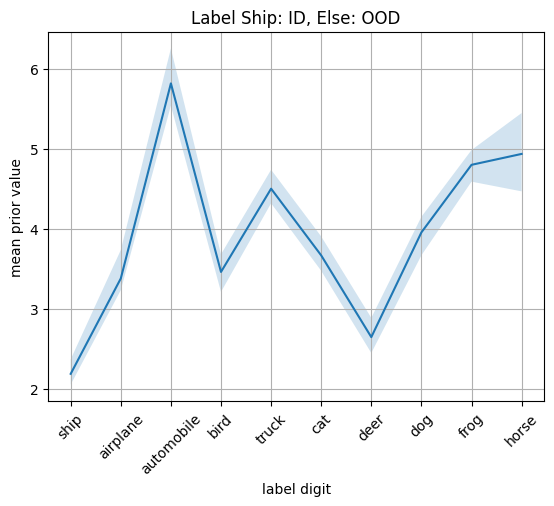

In [ ]:
mean_labels  = np.mean(total_labels, axis=0)
max_labels  = np.max(total_labels, axis=0)
min_labels  = np.min(total_labels, axis=0)
print(total_labels.shape)
print(total_labels)
print(mean_labels.shape)
plt.plot(x,mean_labels)
plt.fill_between(x, max_labels, min_labels, alpha=0.2)
plt.xlabel('label digit')
plt.ylabel('mean prior value')
if model_name in data_dist:
    if model_name == 'mnist':
        plt.xticks(range(0, 10, 1))
        plt.title('label 0: ID, 1~9: OOD')
    else:
        plt.title('Ship: ID, Else: OOD')
        plt.xticks(range(0, 10, 1), rotation = 45)
else:
    plt.title('label 0~4: MNIST, 5: CelebA')
    plt.xticks(range(0, 6, 1))
plt.grid(1)

In [129]:
x_arrays_std

array([[[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [1.38777878e-17, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00]],

       [[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 8.67361738e-19, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+0

0.0


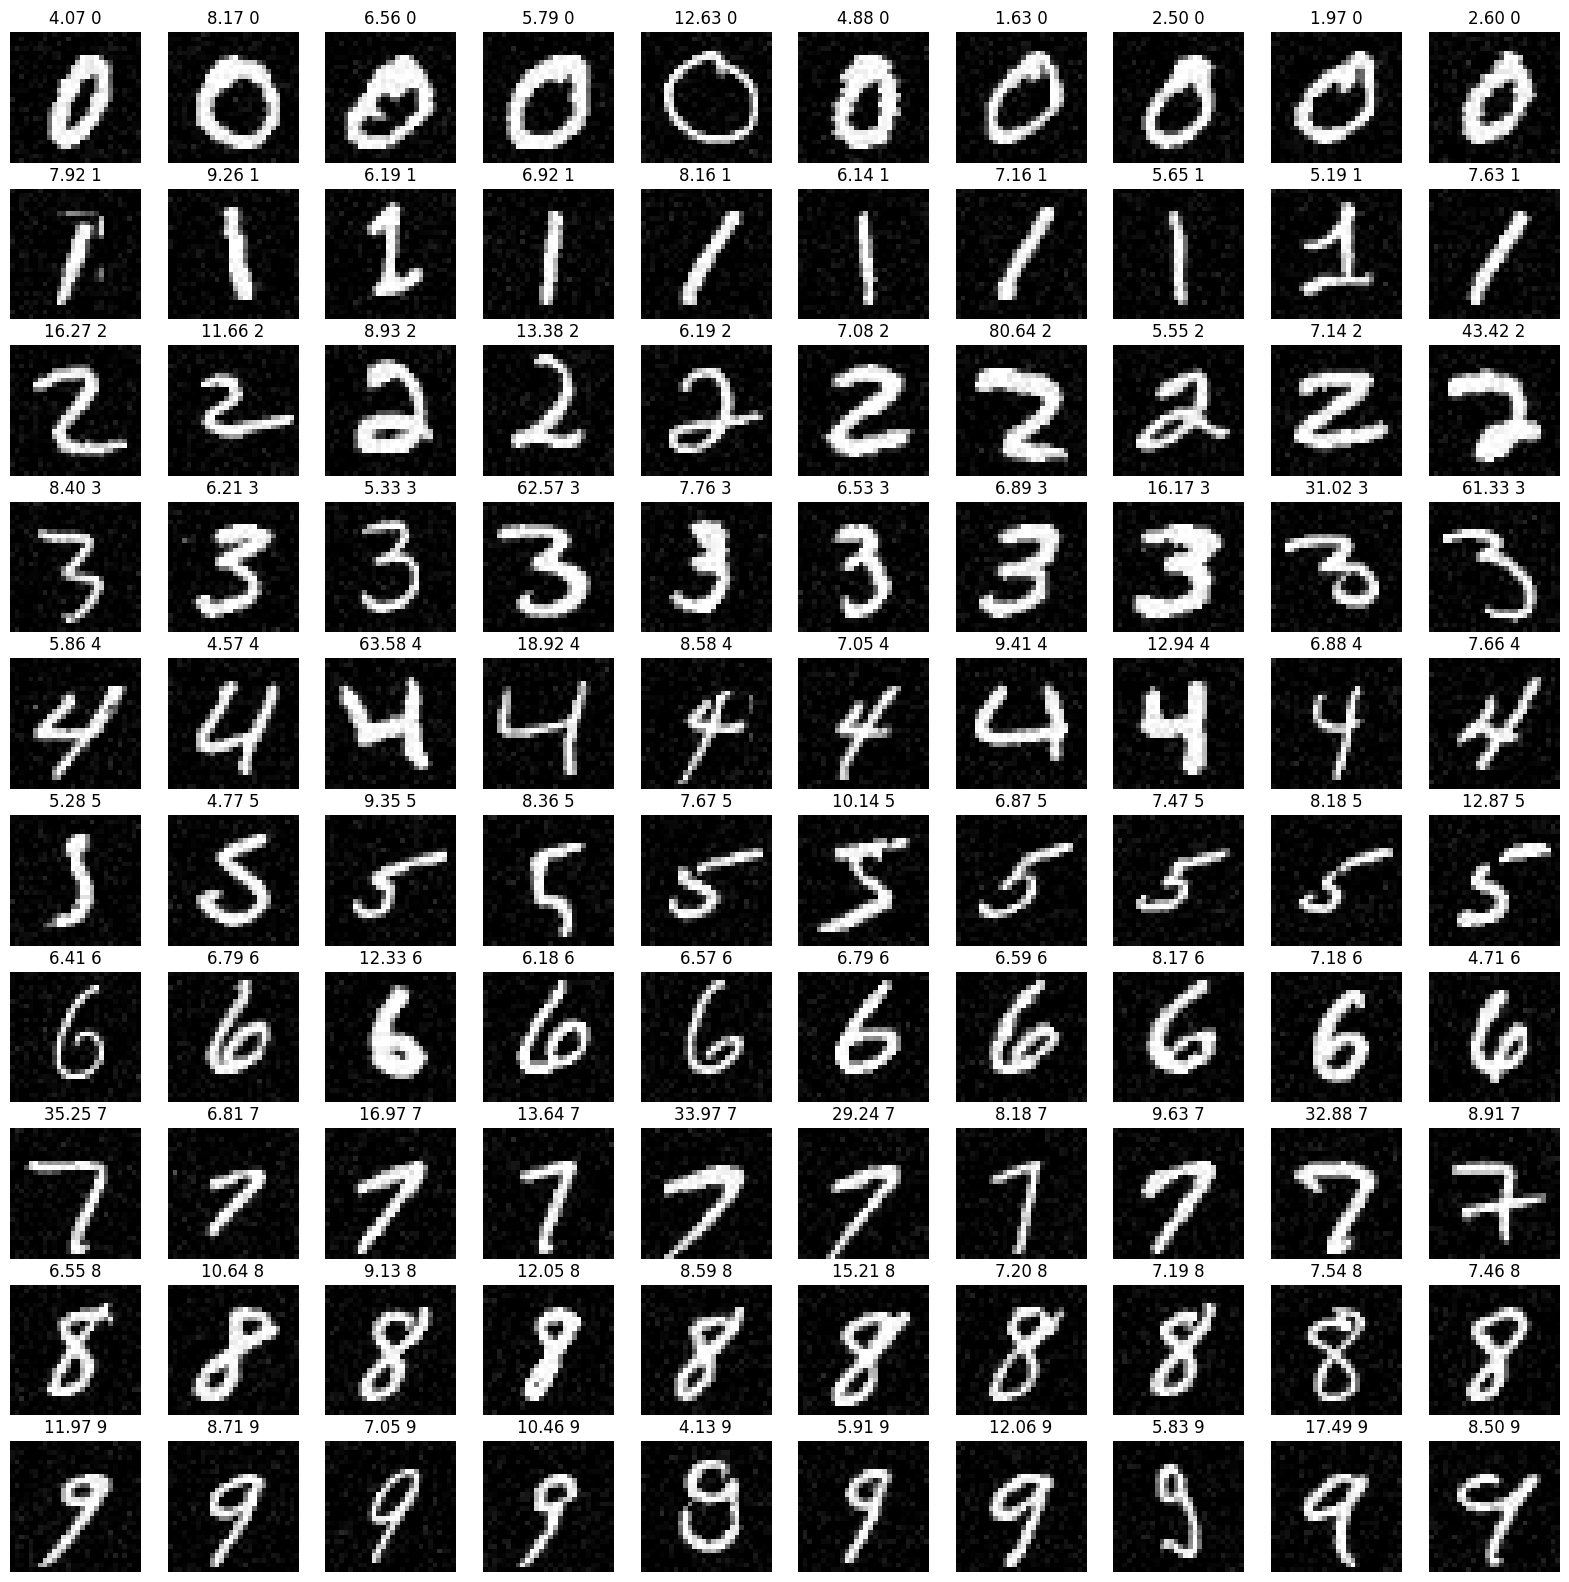

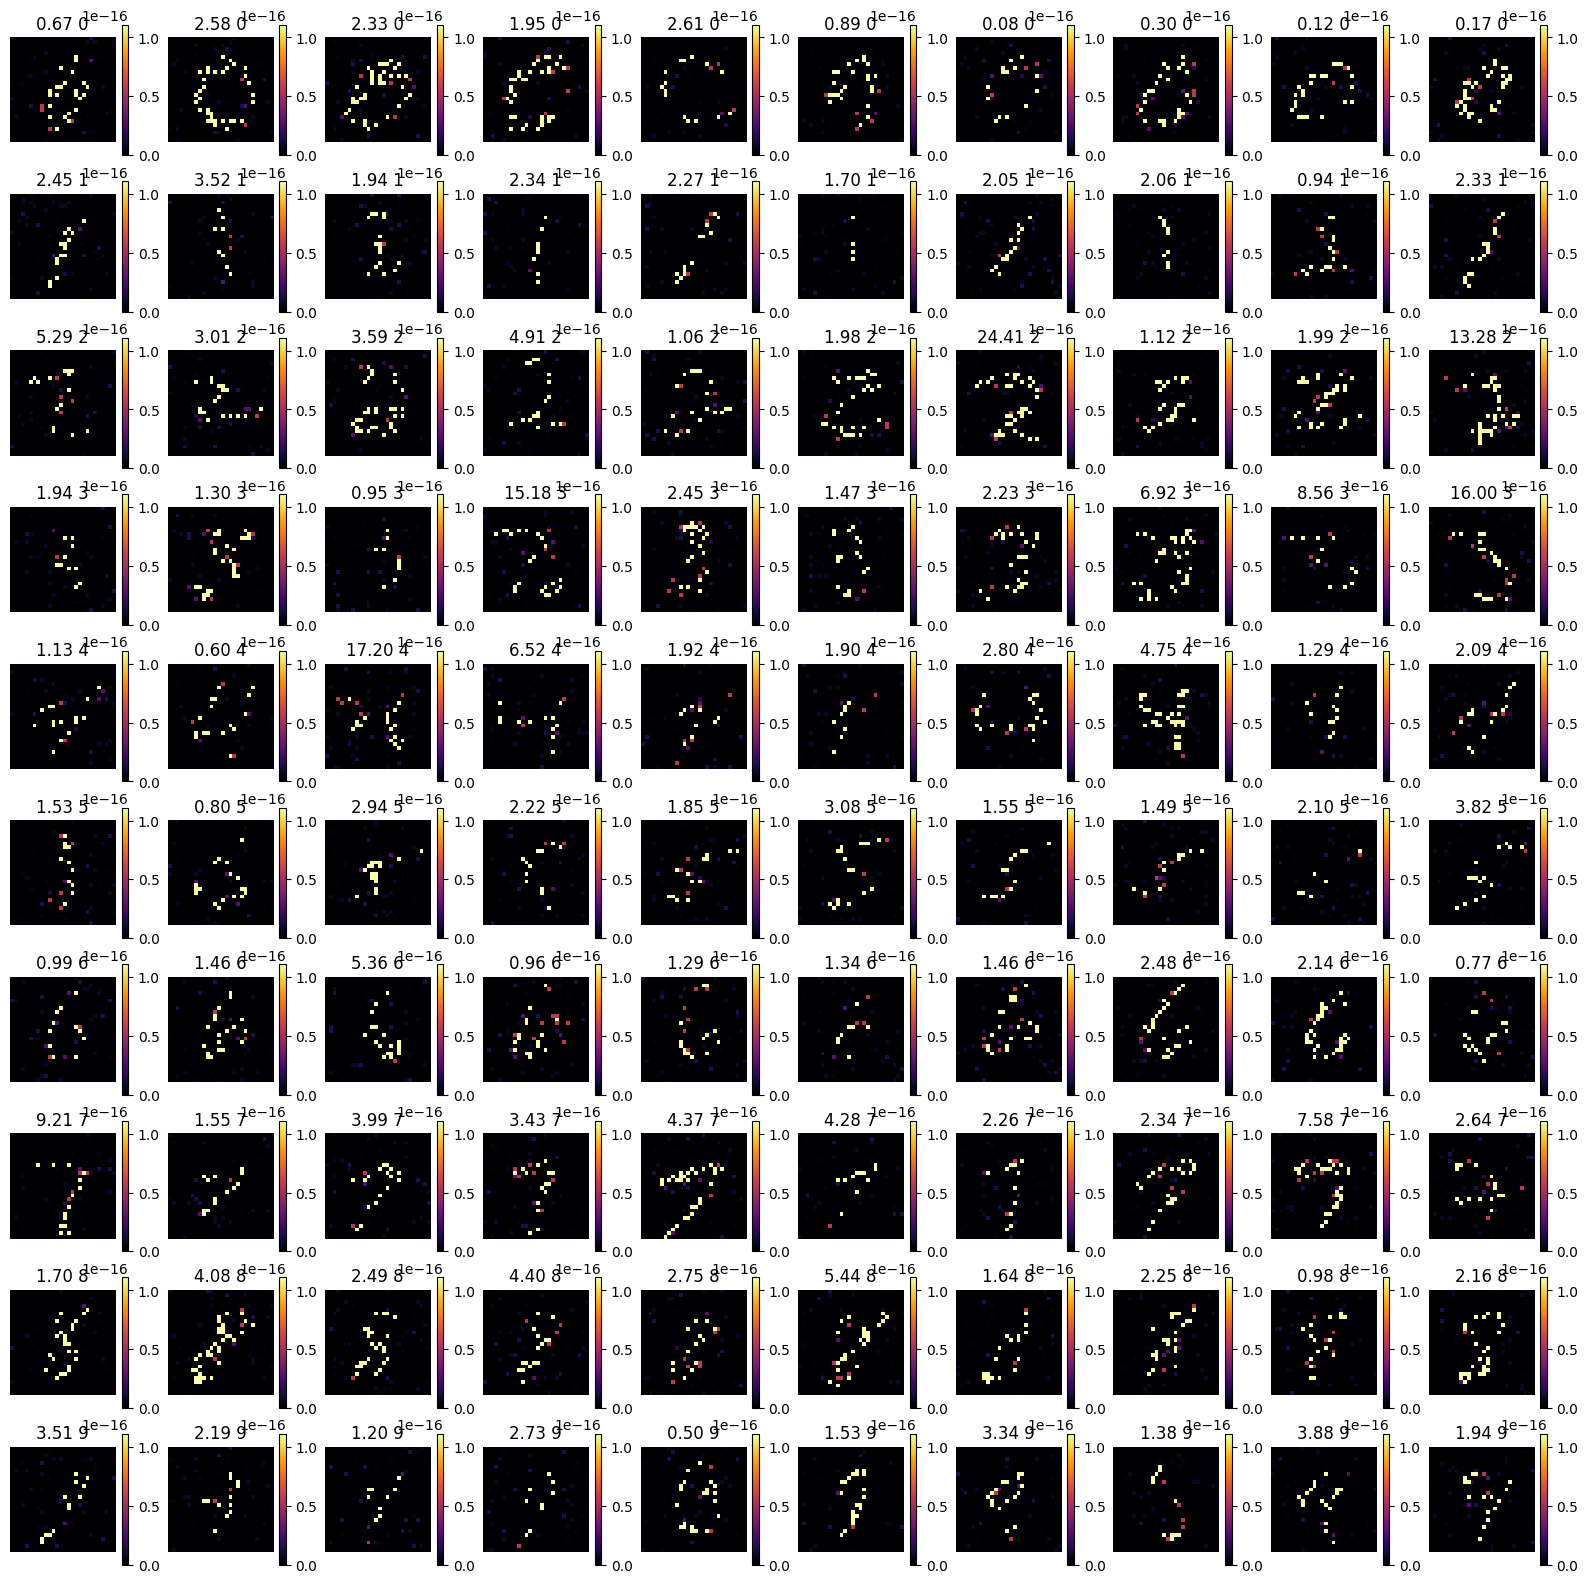

In [170]:
x_arrays_std = np.std(x_arrays, axis = 0)
x_arrays_mean = np.mean(x_arrays, axis = 0)

p_arrays_std = np.std(p_arrays, axis = 0)
p_arrays_mean = np.mean(p_arrays, axis = 0)
norm_x_std = x_arrays_std/np.max(x_arrays_std)

# print(p_arrays_std.max(), p_arrays_std.min())
print(x_arrays_std[:,0,:].max())

# print(x_arrays_std/np.max(x_arrays_std))
# print((x_arrays_std/np.max(x_arrays_std)).max())
# print(norm_x_std.max())
# print(x_arrays_std.shape, x_arrays_mean.shape)
# print(p_arrays_std.shape, p_arrays_mean.shape)
plt.figure(figsize = (20,20))
for i in range(100):
    plt.subplot(10,10,i+1)
    if model_name == 'cifar':
        plt.imshow(x_arrays_mean[i,0].squeeze().reshape(32,32))
    else:
        plt.imshow(x_arrays_mean[i,1].squeeze().reshape(28,28), cmap='gray')
    plt.grid(0)
    plt.axis('off')
    plt.title(f'{p_arrays_mean[i,1]:.2f} {label_list_[i]}')
    plt.clim([0,1])
    
plt.show()



plt.figure(figsize = (20,20))
for i in range(100):
    plt.subplot(10,10,i+1)
    if model_name == 'cifar':
        plt.imshow(x_arrays_std[i,0].squeeze().reshape(32,32/x_arrays_std.max()))
    else:
        # log_std_map = np.log(x_arrays_std[i,0].squeeze().reshape(28,28)/x_arrays_std.max()+1e-16)
        # normalized_log_std = (log_std_map - np.min(log_std_map)) / (np.max(log_std_map) - np.min(log_std_map))
        plt.imshow(x_arrays_std[i,1].squeeze().reshape(28,28), cmap = 'inferno')
    plt.grid(0)
    plt.axis('off')
    plt.title(f'{p_arrays_std[i,1]:.2f} {label_list_[i]}')
    plt.clim([0, x_arrays_std.max()])
    plt.colorbar()
    
plt.show()

[[0.    0.    0.    ... 0.    0.    0.   ]
 [0.    0.    0.    ... 0.    0.    0.   ]
 [0.125 0.    0.    ... 0.    0.    0.   ]
 [0.    0.    0.    ... 0.    0.    0.   ]
 [0.    0.    0.    ... 0.    0.    0.   ]]
(5, 784)
1.0


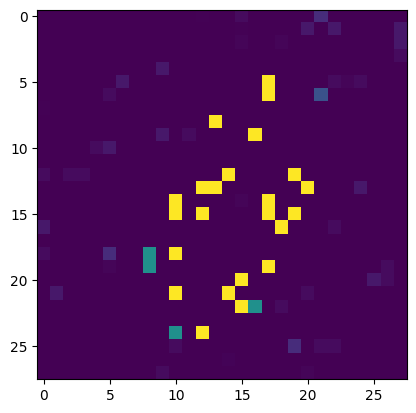

In [165]:
# temps = np.log(x_arrays_std + 1e-32)
# temp = temps[i,0].squeeze().reshape(28,28) / temps.max()

# print(temp.min())

# temp = (np.log(x_arrays_std+ 1e-32) )/ np.log(x_arrays_std.max())
# temp = (temp - temp.min()) / (temp.max() - temp.min())
# plt.imshow(norm_x_std[0,0,:].squeeze().reshape(28,28))
# x_arrays_std *= 1e16
x_arrays_std = np.std(x_arrays[:,0,:].squeeze(), axis = 0)
print(x_arrays_std/np.max(x_arrays_std))
# x_arrays_std_ = (x_arrays_std - x_arrays_std.min()) / (x_arrays_std.max() - x_arrays_std.min())
x_arrays_std_ = x_arrays_std/np.max(x_arrays_std)
print(x_arrays_std_.shape)
print(x_arrays_std_[1,:].max())
plt.imshow(x_arrays_std_[1,:].squeeze().reshape(28,28))

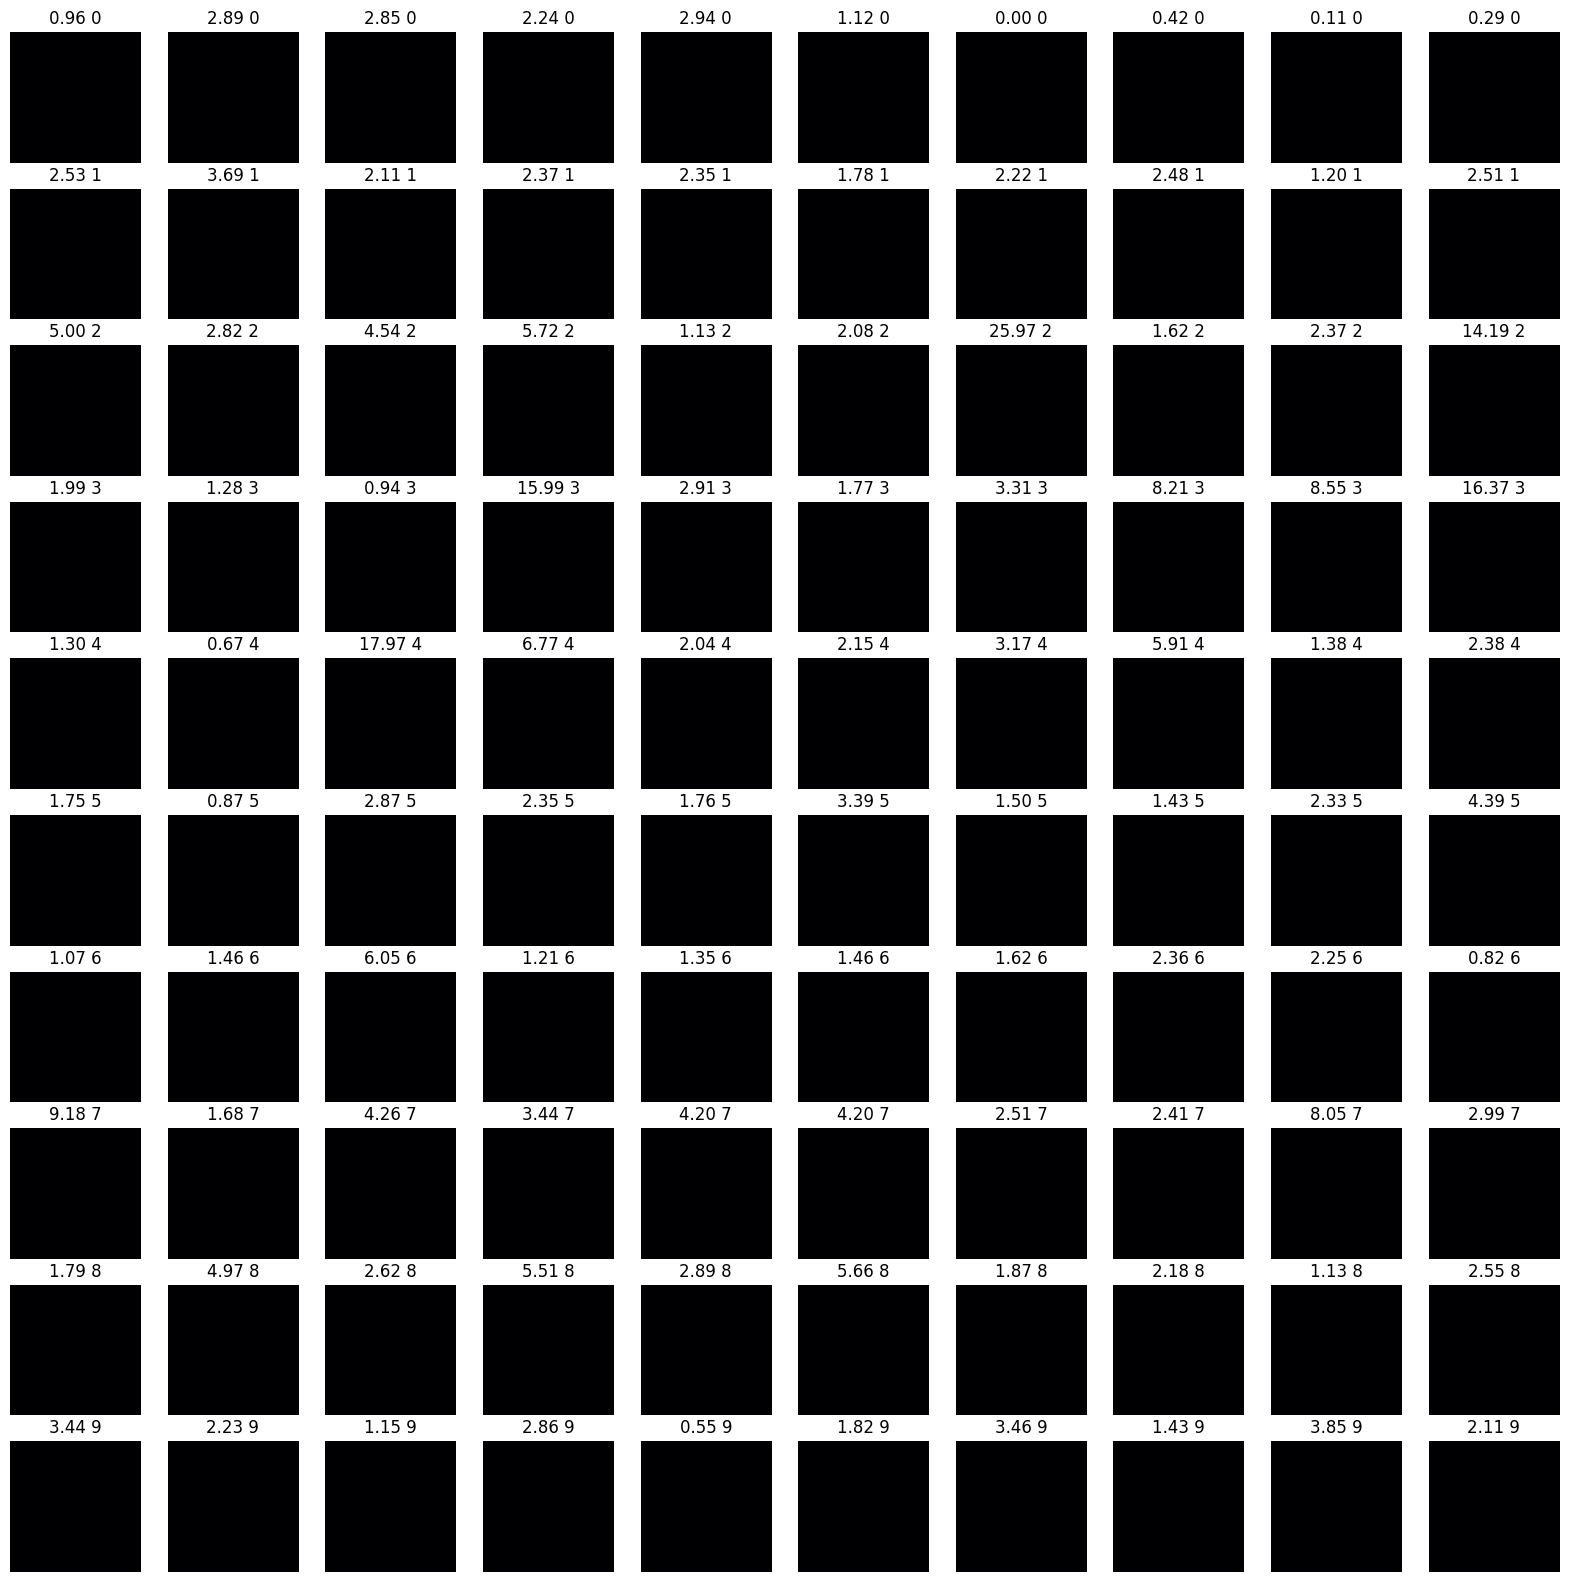

In [79]:
plt.figure(figsize = (20,20))
for i in range(100):
    plt.subplot(10,10,i+1)
    if model_name == 'cifar':
        plt.imshow(x_arrays_std[i,0].squeeze().reshape(32,32/x_arrays_std.max()))
    else:
        log_std_map = np.log1p(x_arrays_std[i,0].squeeze().reshape(28,28)/x_arrays_std.max())
        # normalized_log_std = (log_std_map - np.min(log_std_map)) / (np.max(log_std_map) - np.min(log_std_map))
        plt.imshow(x_arrays_std[i,0].squeeze().reshape(28,28)/x_arrays_std.max(), cmap='inferno')
    plt.grid(0)
    plt.axis('off')
    plt.title(f'{p_arrays_std[i,0]:.2f} {label_list_[i]}')
    
plt.show()

In [ ]:
idx_list = np.array(np.linspace(30,55,5), dtype = np.int32)
print(idx_list)
print(df.shape)
df = df_.iloc[idx_list, col_idx]
p_array = df.values
x_array = x_array_[idx_list, :, :][:, col_idx, :]

label_list = label_list_[idx_list]
print(x_array.shape)
print(p_array.shape)



[30 36 42 48 55]
(5, 5)
(5, 5, 784)
(5, 5)


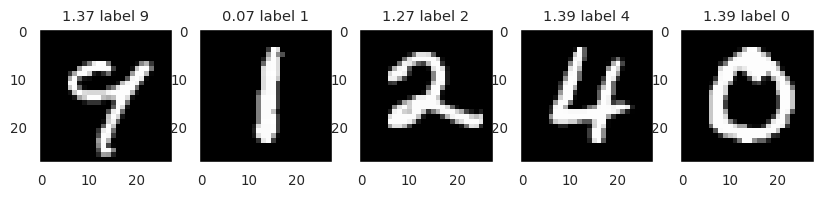

In [145]:
plt.figure(figsize=(10,25))
for i in range(5):
    plt.subplot(1,5,1+i)
    plt.imshow(x_array[i,0].reshape(img_size), cmap = 'gray')
    plt.title(f'{p_array[i,0]:.2f} label {label_list[i]}')
    plt.grid(0)

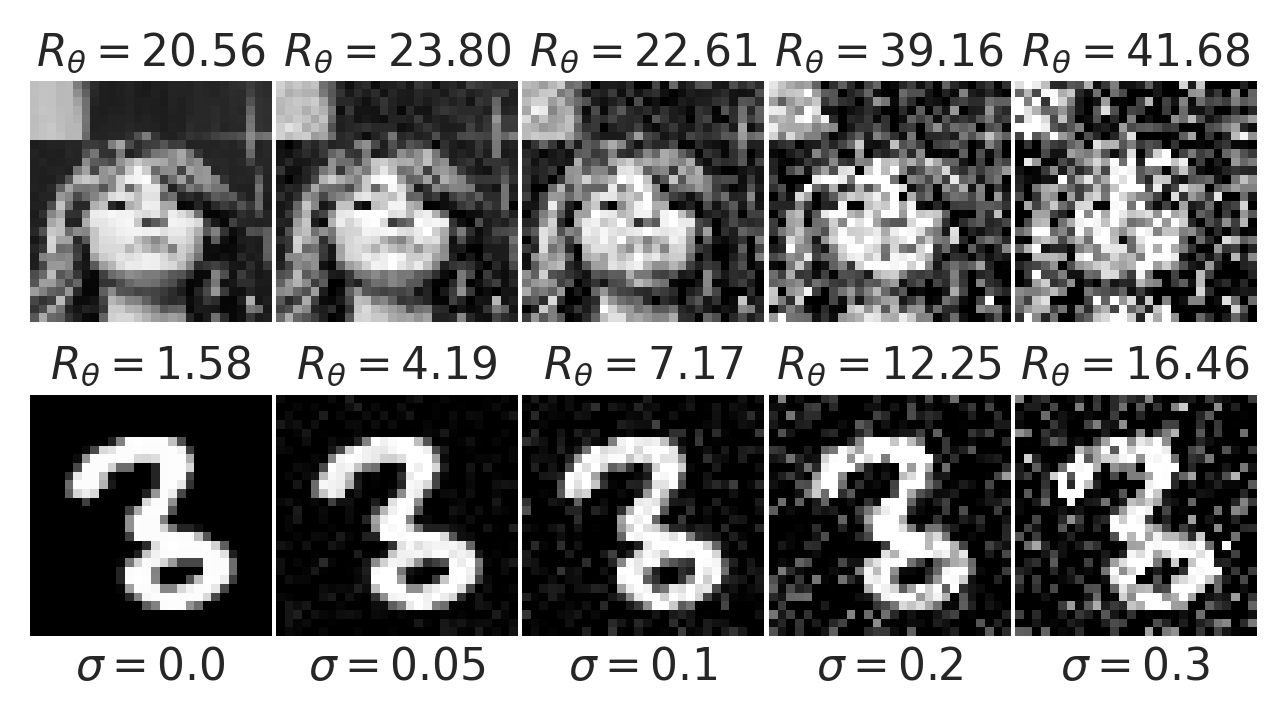

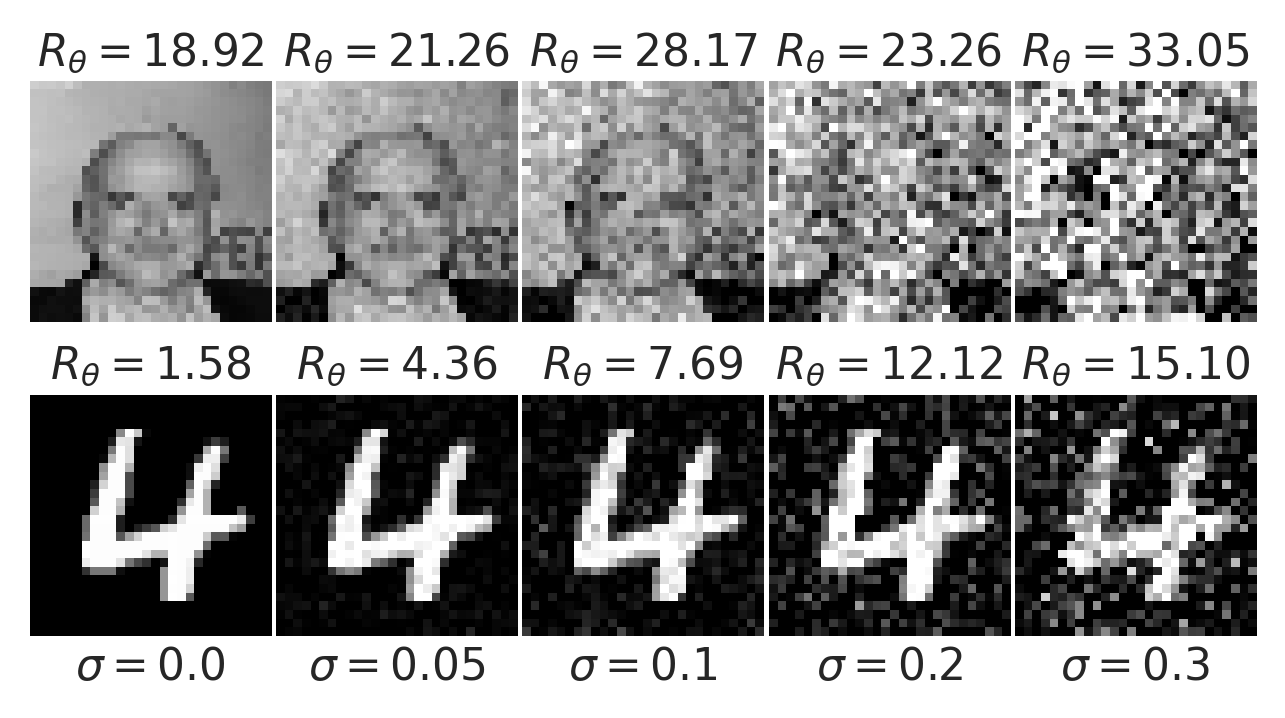

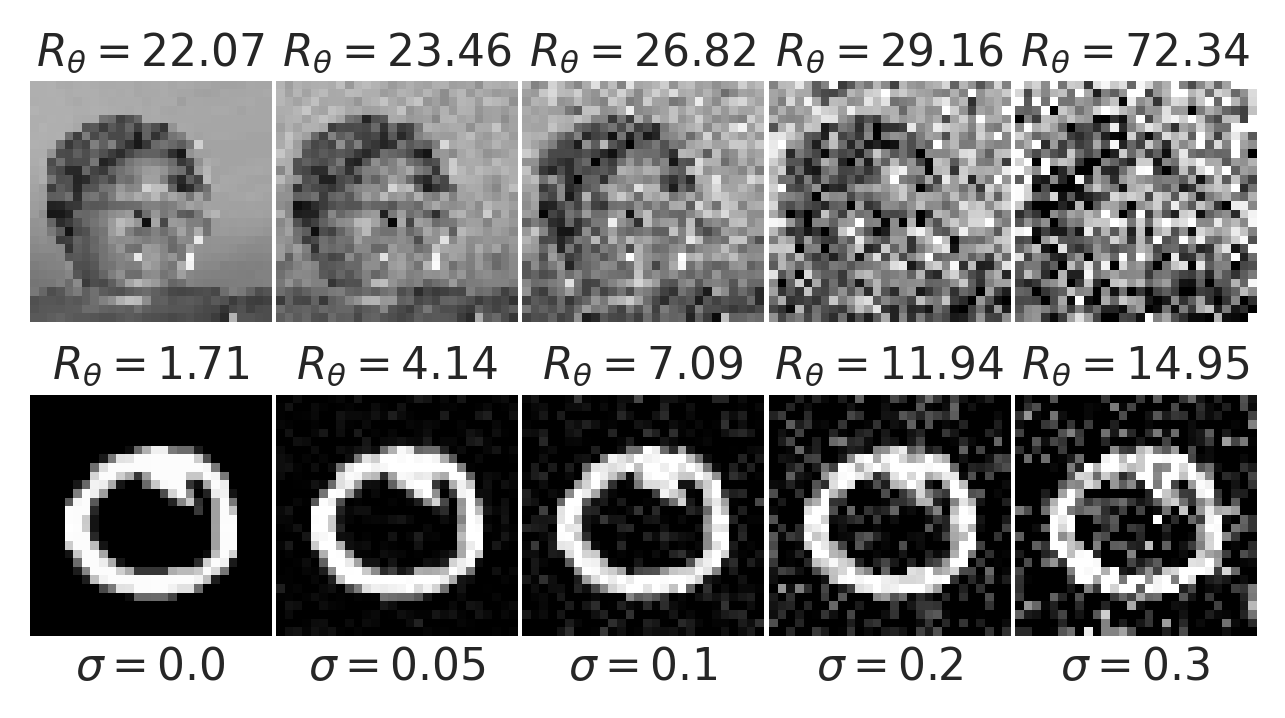

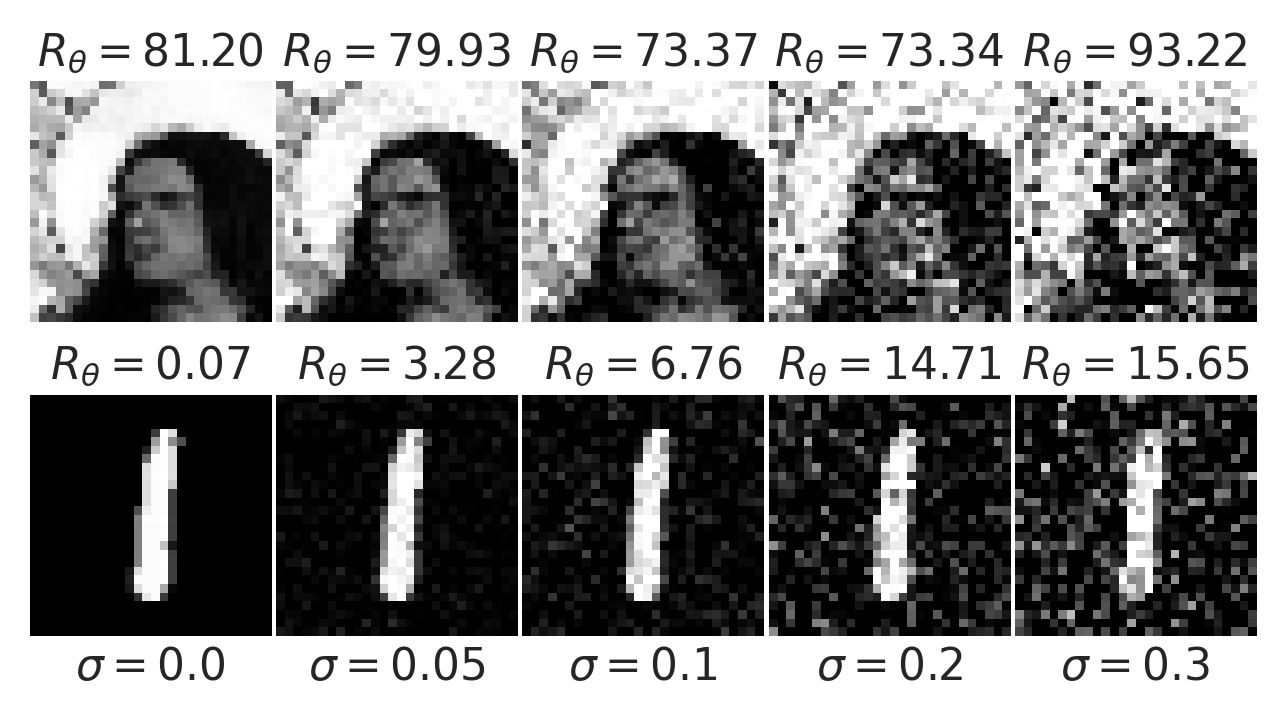

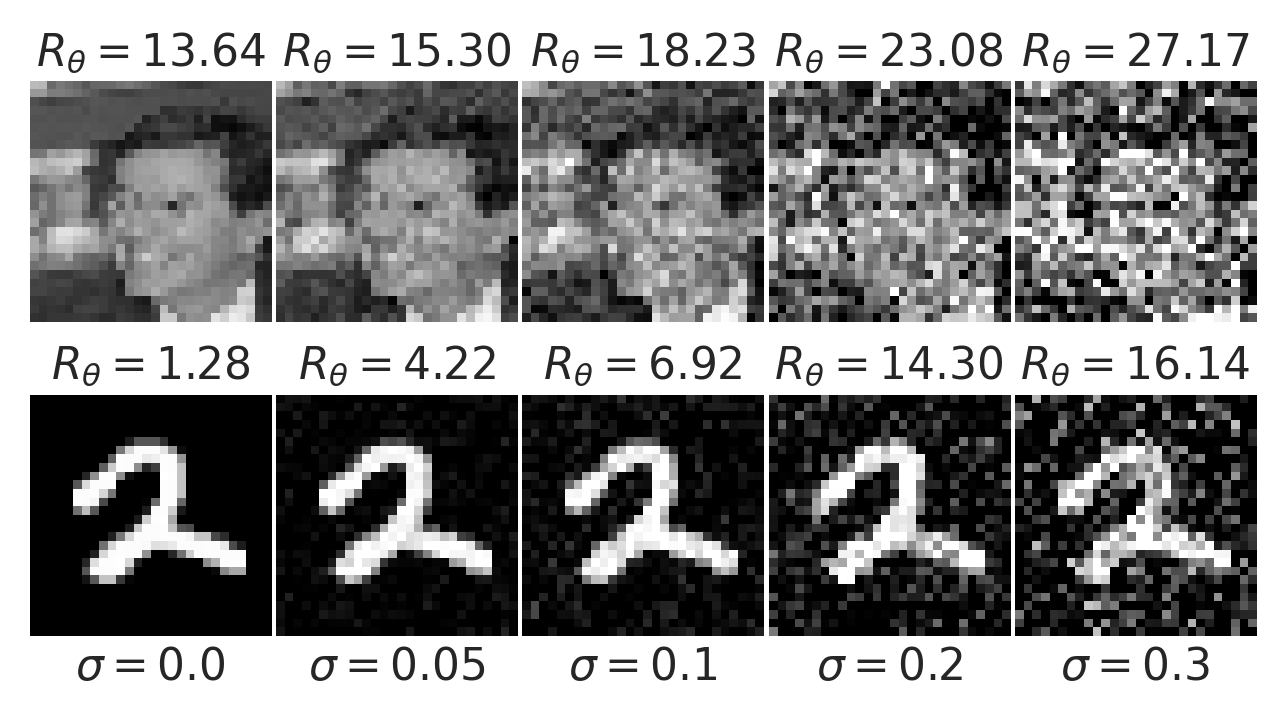

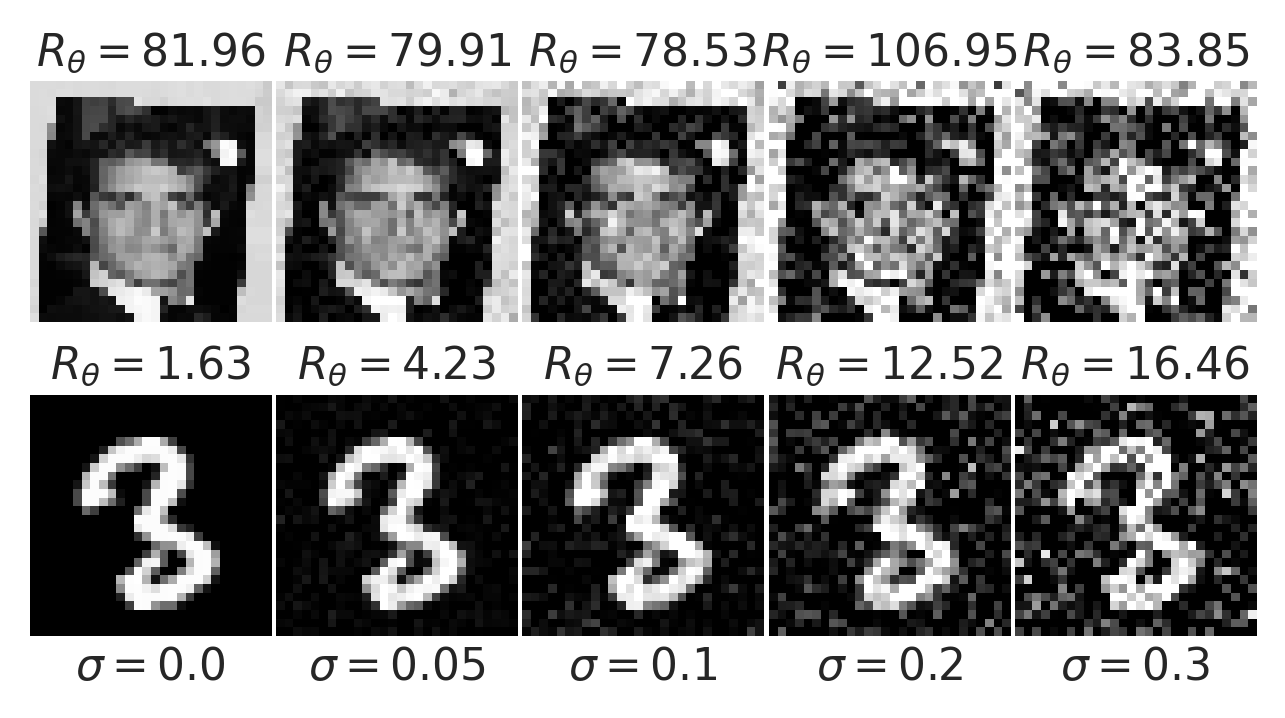

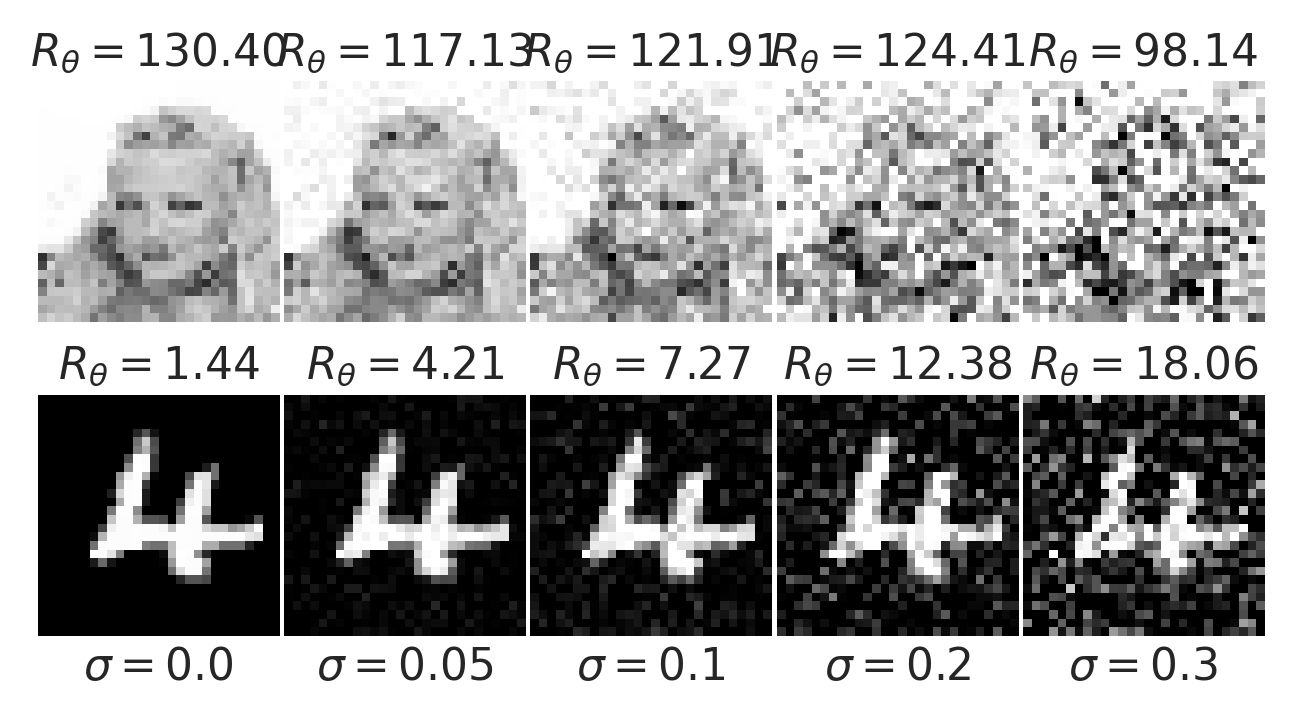

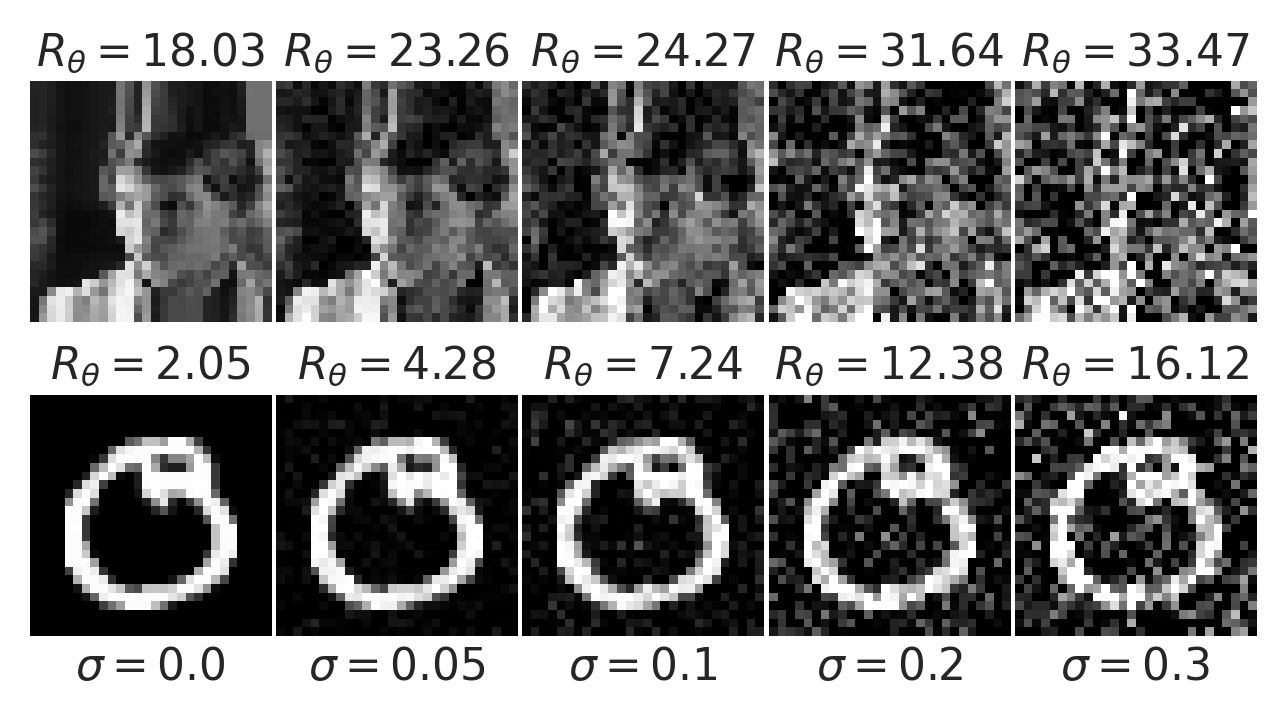

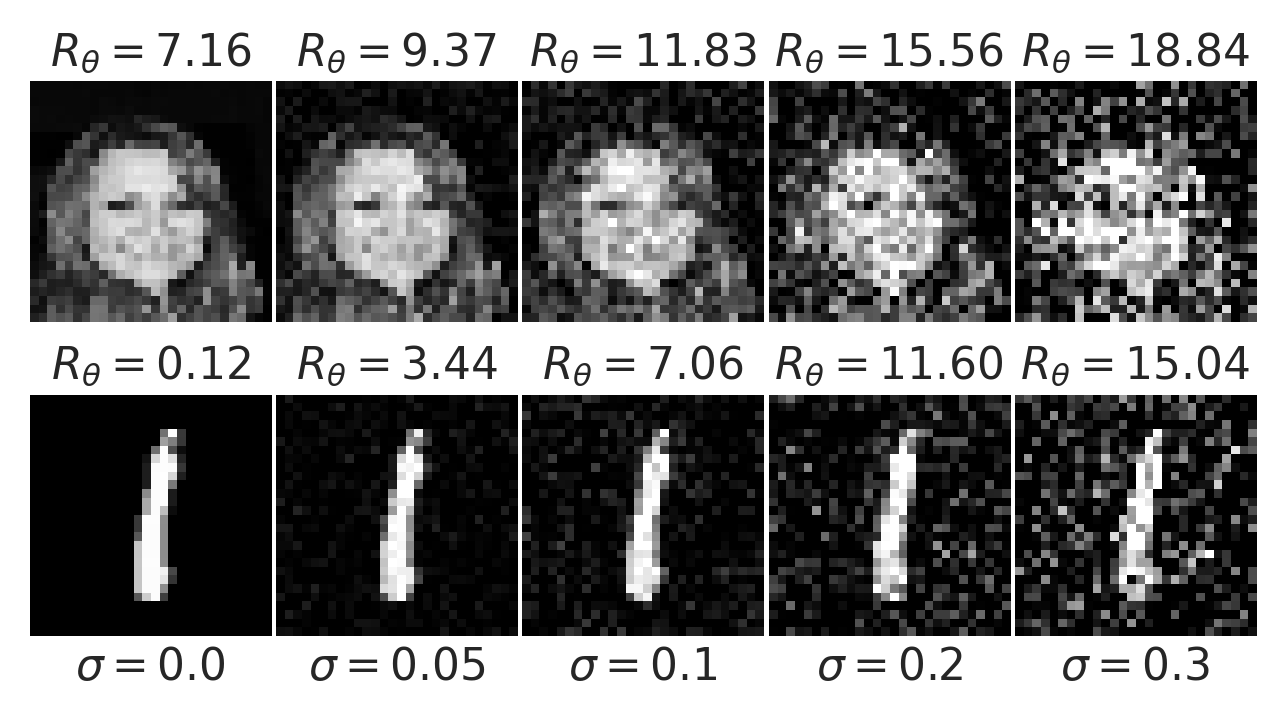

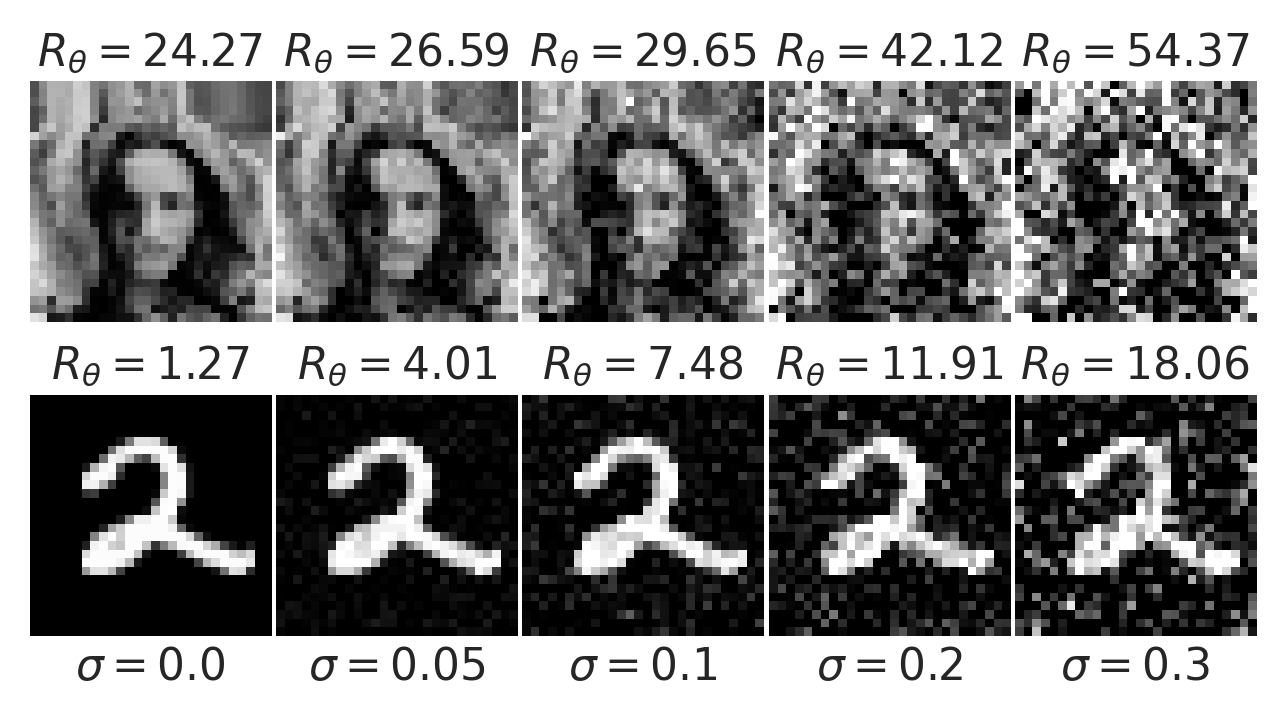

In [21]:
for i in range(10):
    idx_list = [i, i+50]
    df = df_.iloc[idx_list, col_idx]
    p_array = df.values
    x_array = x_array_[idx_list, :, :][:, col_idx, :]

    sns.set()
    sns.set_context("paper", font_scale=1.1)

    nc, nr = len(col_idx), len(idx_list)
    figw = 6
    figh = figw * nr / nc
    fig = plt.figure(figsize=(figw, figh), dpi=300)
    gs = GridSpec(nr, nc, wspace=-0.4, hspace=0.3)
    for i in range(nr):
        for j in range(nc):
            ax = fig.add_subplot(gs[i, j])
            ax.imshow(
                x_array[i, j].reshape(img_size),
                cmap="gray",
                interpolation="none",
                vmin=0,
                vmax=1,
            )
            ax.axis("off")
            ax.annotate(
                r"$R_\theta = {:.2f}$".format(p_array[i, j]),
                xy=(0.5, 1.07),
                xycoords="axes fraction",
                ha="center",
            )
            if i == 0:
                if perturb_mode == "convex":
                    symbol = r"$\lambda$"
                else:
                    symbol = r"$\sigma$"
                ax.annotate(
                    r"{}$={}$".format(symbol, df.columns[j]),
                    xy=(0.5, -1.48),
                    xycoords="axes fraction",
                    ha="center",
                )

    plt.show()
    os.makedirs(fig_dir, exist_ok=True)
    fig.savefig(
        os.path.join(fig_dir, f"mnist_{perturb_mode}_{i}.png"),
        bbox_inches="tight",
    )